# TARDIS

In [9]:
import pandas as pd
import numpy as np

In [10]:
df = pd.read_csv("dataset.csv", sep=";")
print("(Nb rows, Nb columns): ", df.shape)
df.info()

(Nb rows, Nb columns):  (12070, 26)
<class 'pandas.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                         Non-Null Count  Dtype
---  ------                                                                         --------------  -----
 0   Date                                                                           12010 non-null  str  
 1   Service                                                                        11830 non-null  str  
 2   Departure station                                                              12011 non-null  str  
 3   Arrival station                                                                12011 non-null  str  
 4   Average journey time                                                           11830 non-null  str  
 5   Number of scheduled trains                                                     11830 non-null  str  
 6   Number of can

In [11]:
nb_duplicates = df.duplicated().sum()

if nb_duplicates > 0:
    df = df.drop_duplicates()

print("Nb duplicates: ", nb_duplicates)
print("(Nb rows, Nb columns): ", df.shape)

Nb duplicates:  174
(Nb rows, Nb columns):  (11896, 26)


## Data Cleaning

In [12]:
df['Date'] = df['Date'].str.replace('/', '-')
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m', errors="coerce")

numeric_cols = ['Average journey time',
                'Number of scheduled trains',
                'Number of cancelled trains',
                'Number of trains delayed at departure',
                'Average delay of late trains at departure',
                'Average delay of all trains at departure',
                'Number of trains delayed at arrival',
                'Average delay of late trains at arrival',
                'Average delay of all trains at arrival',
                'Number of trains delayed > 15min',
                'Average delay of trains > 15min (if competing with flights)',
                'Number of trains delayed > 30min',
                'Number of trains delayed > 60min',
                'Pct delay due to external causes',
                'Pct delay due to infrastructure',
                'Pct delay due to traffic management',
                'Pct delay due to rolling stock',
                'Pct delay due to station management and equipment reuse',
                'Pct delay due to passenger handling (crowding, disabled persons, connections)']

for col in numeric_cols:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[numeric_cols] = df[numeric_cols].fillna(0)

df.info()

<class 'pandas.DataFrame'>
Index: 11896 entries, 0 to 12060
Data columns (total 26 columns):
 #   Column                                                                         Non-Null Count  Dtype         
---  ------                                                                         --------------  -----         
 0   Date                                                                           11594 non-null  datetime64[us]
 1   Service                                                                        11656 non-null  str           
 2   Departure station                                                              11837 non-null  str           
 3   Arrival station                                                                11837 non-null  str           
 4   Average journey time                                                           11896 non-null  float64       
 5   Number of scheduled trains                                                     11896 non-null  fl

In [13]:
df['Departure station'] = df['Departure station'].str.strip().str.upper()
df['Arrival station'] = df['Arrival station'].str.strip().str.upper()

In [14]:
print(df.isnull().sum())

Date                                                                               302
Service                                                                            240
Departure station                                                                   59
Arrival station                                                                     59
Average journey time                                                                 0
Number of scheduled trains                                                           0
Number of cancelled trains                                                           0
Cancellation comments                                                            11324
Number of trains delayed at departure                                                0
Average delay of late trains at departure                                            0
Average delay of all trains at departure                                             0
Departure delay comments                   

In [15]:
df = df.dropna(subset=['Date', 'Departure station', 'Arrival station'])
print("(Nb rows, Nb columns): ", df.shape)

(Nb rows, Nb columns):  (11478, 26)


## Feature Engineering

In [16]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [17]:
df['Total trains'] = df['Number of scheduled trains']
df['Cancellation rate'] = df['Number of cancelled trains'] / df['Total trains'].replace(0, np.nan)
df['Delay rate'] = df['Number of trains delayed at arrival'] / df['Total trains'].replace(0, np.nan)
df[['Cancellation rate', 'Delay rate']] = df[['Cancellation rate', 'Delay rate']].fillna(0)

In [18]:
df['Delay severity'] = pd.cut(
    df['Delay rate'],
    bins=[-0.1, 0.1, 0.2, 1.0],
    labels=['Low', 'Medium', 'High']
)

In [19]:
df[['Year', 'Month', 'Delay severity']].sample(5)

,Year,Month,Delay severity
10926,2025,5,Low
3432,2020,4,High
9200,2024,3,Medium
9135,2024,3,Low
8102,2023,6,Medium


<Axes: title={'center': 'Distribution of delay severity'}, xlabel='Delay severity'>

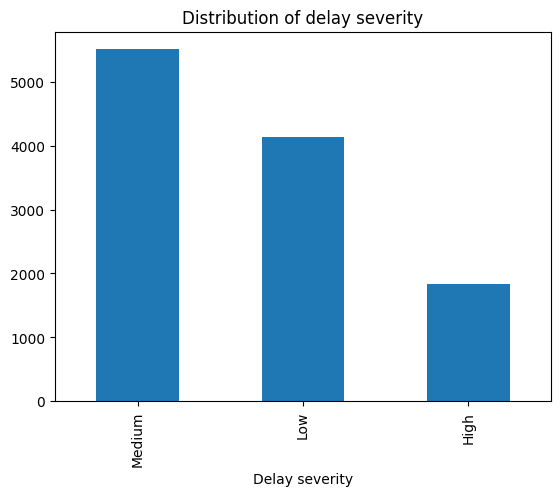

In [20]:
df['Delay severity'].value_counts().plot(kind='bar', title='Distribution of delay severity')

In [21]:
df.to_csv('cleaned_dataset.csv', index=False)